# PCA for Handwritten Digit Recognition

Compare a k-nearest-neighbors classifier on the original 64-pixel digit features with the same classifier after PCA. The dataset comes with scikit-learn, so this notebook can run without a separate CSV.


In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import seaborn as sns

from IPython.display import Markdown, display

from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TEST_SIZE = 0.25

np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="tab10",
    rc={
        "figure.figsize": (10, 6),
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
    },
)


## Workflow


### Method


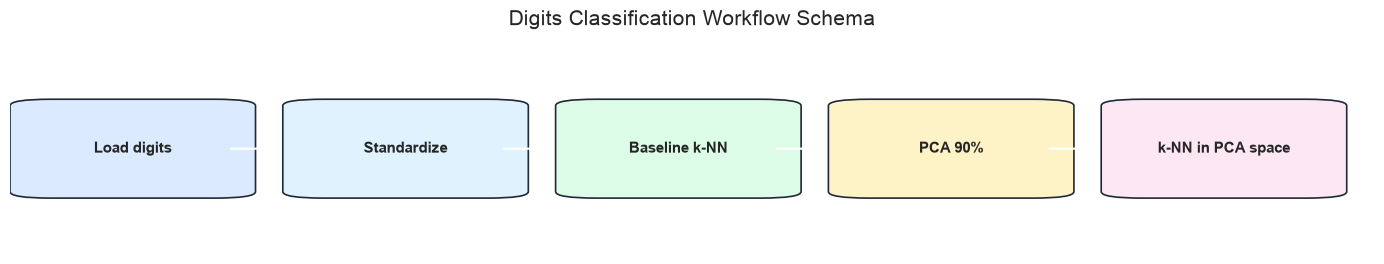

In [2]:
fig, ax = plt.subplots(figsize=(14, 2.8))
ax.axis("off")

stages = [
    ("Load digits", 0.02, "#DBEAFE"),
    ("Standardize", 0.22, "#E0F2FE"),
    ("Baseline k-NN", 0.42, "#DCFCE7"),
    ("PCA 90%", 0.62, "#FEF3C7"),
    ("k-NN in PCA space", 0.82, "#FCE7F3"),
]

for label, x0, color in stages:
    box = FancyBboxPatch(
        (x0, 0.28),
        0.14,
        0.42,
        boxstyle="round,pad=0.02,rounding_size=0.03",
        linewidth=1.2,
        edgecolor="#1F2937",
        facecolor=color,
    )
    ax.add_patch(box)
    ax.text(x0 + 0.07, 0.49, label, ha="center", va="center", fontsize=10.5, weight="bold")

for (_, x0, _), (_, x1, _) in zip(stages[:-1], stages[1:]):
    ax.annotate("", xy=(x1 - 0.02, 0.49), xytext=(x0 + 0.14, 0.49), arrowprops=dict(arrowstyle="->", lw=1.6))

ax.set_title("Digits Classification Workflow Schema", fontsize=15, pad=10)
plt.tight_layout()
plt.show()


## 1. Dataset preparation


In [3]:
digits = load_digits()
X_digits = digits.data
y_digits = digits.target

print(f"Digits matrix shape: {X_digits.shape}")
print(f"Image shape: {digits.images[0].shape}")
print(f"Number of classes: {len(np.unique(y_digits))}")


Digits matrix shape: (1797, 64)
Image shape: (8, 8)
Number of classes: 10


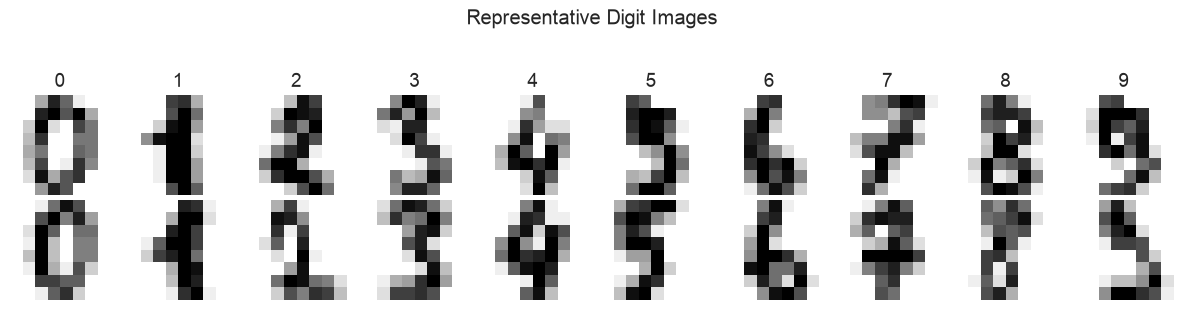

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for digit in range(10):
    idx = np.where(y_digits == digit)[0][0]
    axes[0, digit].imshow(digits.images[idx], cmap="gray_r")
    axes[0, digit].set_title(str(digit))
    axes[0, digit].axis("off")

    idx2 = np.where(y_digits == digit)[0][1]
    axes[1, digit].imshow(digits.images[idx2], cmap="gray_r")
    axes[1, digit].axis("off")

plt.suptitle("Representative Digit Images", y=1.05)
plt.tight_layout()
plt.show()


,digit,count
0,0,178
1,1,182
2,2,177
3,3,183
4,4,181
5,5,182
6,6,181
7,7,179
8,8,174
9,9,180


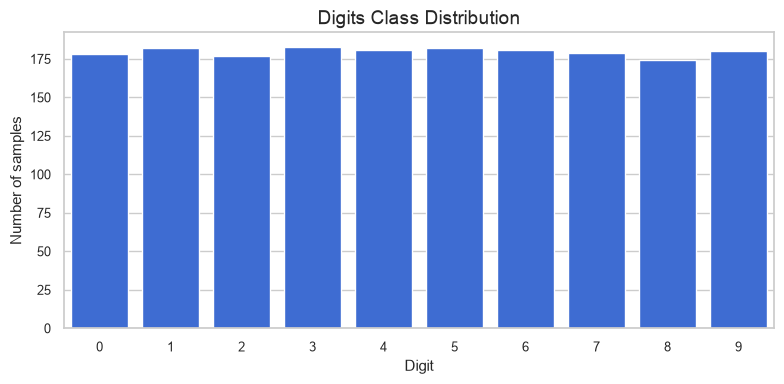

In [5]:
class_distribution = pd.Series(y_digits, name="digit").value_counts().sort_index().reset_index()
class_distribution.columns = ["digit", "count"]
display(class_distribution)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=class_distribution, x="digit", y="count", ax=ax, color="#2563EB")
ax.set_title("Digits Class Distribution")
ax.set_xlabel("Digit")
ax.set_ylabel("Number of samples")
plt.tight_layout()
plt.show()


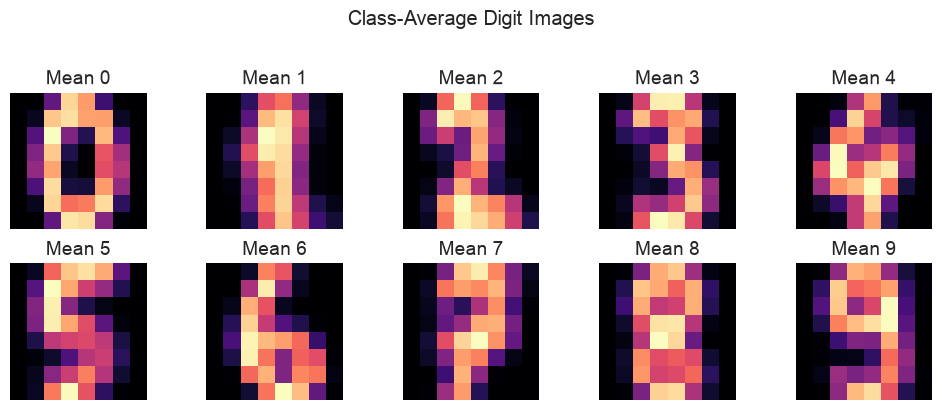

In [6]:
mean_images = np.vstack([digits.images[y_digits == digit].mean(axis=0)[None, ...] for digit in range(10)])

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.ravel()):
    ax.imshow(mean_images[digit], cmap="magma")
    ax.set_title(f"Mean {digit}")
    ax.axis("off")

plt.suptitle("Class-Average Digit Images", y=1.02)
plt.tight_layout()
plt.show()


## 2. Preprocessing


In [7]:
X_train_digits, X_test_digits, y_train_digits, y_test_digits = train_test_split(
    X_digits,
    y_digits,
    test_size=TEST_SIZE,
    stratify=y_digits,
    random_state=RANDOM_STATE,
)

scaler_digits = StandardScaler()
X_train_digits_scaled = scaler_digits.fit_transform(X_train_digits)
X_test_digits_scaled = scaler_digits.transform(X_test_digits)

display(
    pd.DataFrame(
        {
            "matrix": ["X_train", "X_test", "y_train", "y_test"],
            "shape": [
                X_train_digits_scaled.shape,
                X_test_digits_scaled.shape,
                y_train_digits.shape,
                y_test_digits.shape,
            ],
        }
    )
)


,matrix,shape
0,X_train,"(1347, 64)"
1,X_test,"(450, 64)"
2,y_train,"(1347,)"
3,y_test,"(450,)"


## 3. Classifier using original features


In [8]:
knn_original = KNeighborsClassifier(n_neighbors=5)

knn_original.fit(X_train_digits_scaled, y_train_digits)
original_predictions = knn_original.predict(X_test_digits_scaled)

original_accuracy = accuracy_score(y_test_digits, original_predictions)
print(f"Original-space k-NN accuracy: {original_accuracy:.4f}")
print(classification_report(y_test_digits, original_predictions, digits=4))


Original-space k-NN accuracy: 0.9644
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9388    1.0000    0.9684        46
           2     0.9565    1.0000    0.9778        44
           3     0.9783    0.9783    0.9783        46
           4     0.9767    0.9333    0.9545        45
           5     0.9778    0.9565    0.9670        46
           6     0.9778    0.9778    0.9778        45
           7     0.9167    0.9778    0.9462        45
           8     0.9750    0.9070    0.9398        43
           9     0.9535    0.9111    0.9318        45

    accuracy                         0.9644       450
   macro avg     0.9651    0.9642    0.9642       450
weighted avg     0.9651    0.9644    0.9643       450



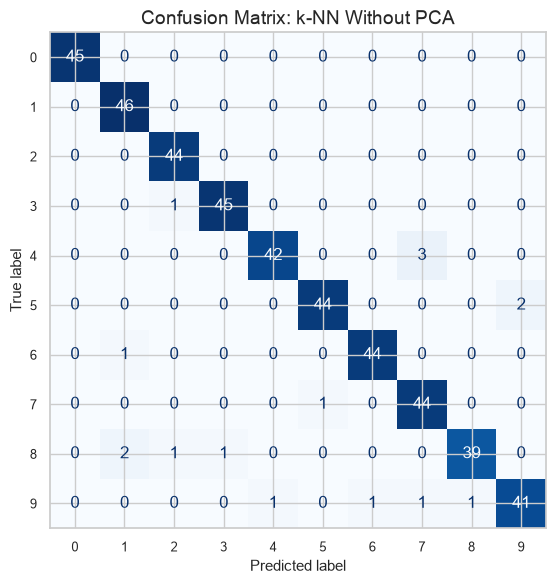

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test_digits,
    original_predictions,
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False,
)
ax.set_title("Confusion Matrix: k-NN Without PCA")
plt.tight_layout()
plt.show()


## 4. Principal component analysis


In [10]:
pca_digits_full = PCA()
pca_digits_full.fit(X_train_digits_scaled)

digits_variance = pca_digits_full.explained_variance_ratio_
digits_cumulative = np.cumsum(digits_variance)
n_components_90 = int(np.searchsorted(digits_cumulative, 0.90) + 1)

digits_variance_table = pd.DataFrame(
    {
        "component": np.arange(1, len(digits_variance) + 1),
        "explained_variance_ratio": digits_variance,
        "cumulative_variance": digits_cumulative,
    }
)

print(f"Components required for at least 90% variance: {n_components_90}")
display(digits_variance_table.head(15))


Components required for at least 90% variance: 31


,component,explained_variance_ratio,cumulative_variance
0,1,0.119181,0.119181
1,2,0.096687,0.215868
2,3,0.083441,0.299309
3,4,0.067026,0.366335
4,5,0.048511,0.414846
5,6,0.044595,0.459440
6,7,0.039154,0.498594
7,8,0.033543,0.532137
8,9,0.029802,0.561939
9,10,0.029034,0.590973


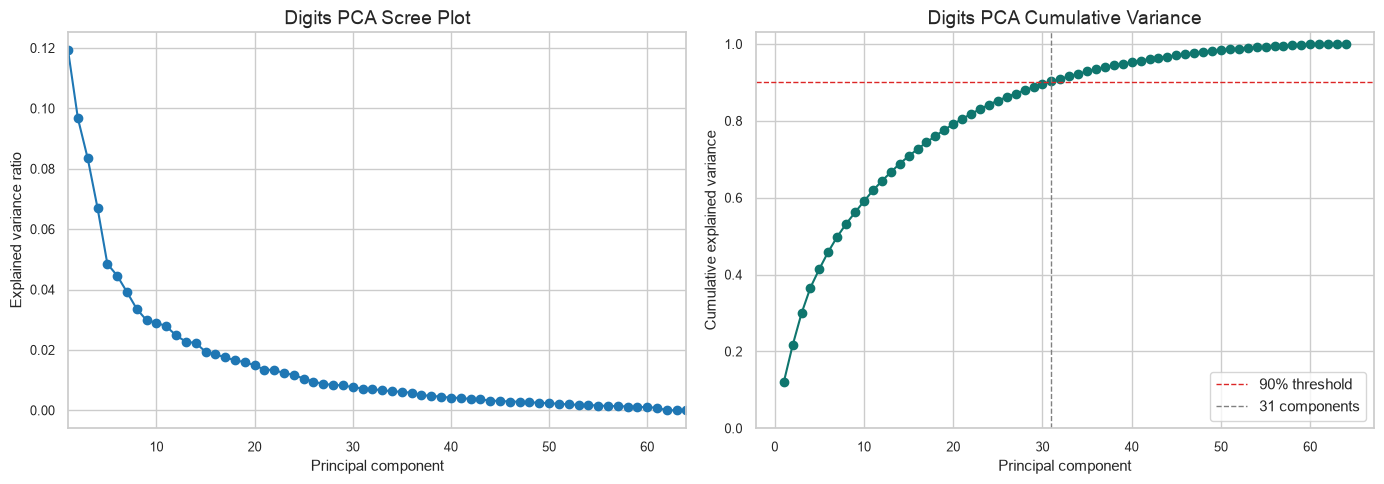

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(digits_variance_table["component"], digits_variance_table["explained_variance_ratio"], marker="o", linewidth=1.5)
axes[0].set_title("Digits PCA Scree Plot")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance ratio")
axes[0].set_xlim(1, 64)

axes[1].plot(digits_variance_table["component"], digits_variance_table["cumulative_variance"], marker="o", linewidth=1.5, color="#0F766E")
axes[1].axhline(0.90, linestyle="--", color="#DC2626", linewidth=1, label="90% threshold")
axes[1].axvline(n_components_90, linestyle="--", color="gray", linewidth=1, label=f"{n_components_90} components")
axes[1].set_title("Digits PCA Cumulative Variance")
axes[1].set_xlabel("Principal component")
axes[1].set_ylabel("Cumulative explained variance")
axes[1].set_ylim(0, 1.03)
axes[1].legend()

plt.tight_layout()
plt.show()


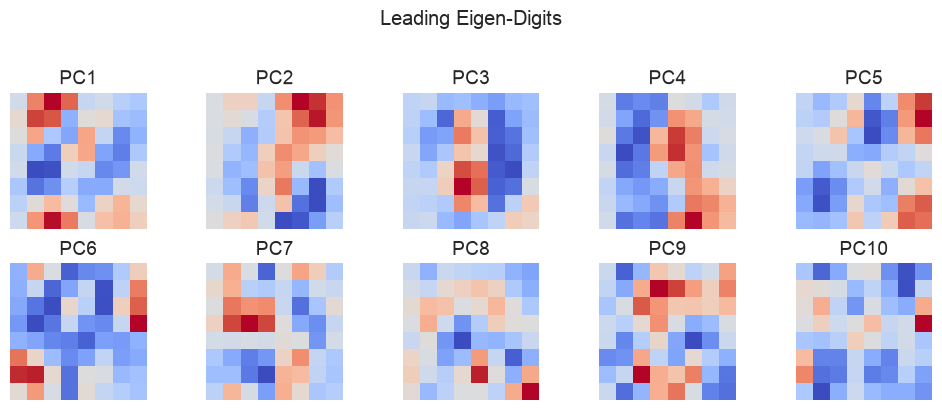

In [12]:
eigen_digits = pca_digits_full.components_[:10].reshape(10, 8, 8)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for idx, ax in enumerate(axes.ravel()):
    ax.imshow(eigen_digits[idx], cmap="coolwarm")
    ax.set_title(f"PC{idx + 1}")
    ax.axis("off")

plt.suptitle("Leading Eigen-Digits", y=1.02)
plt.tight_layout()
plt.show()


## 5. Classifier using PCA features


In [13]:
pca_digits_90 = PCA(n_components=0.90, svd_solver="full")

X_train_digits_pca = pca_digits_90.fit_transform(X_train_digits_scaled)
X_test_digits_pca = pca_digits_90.transform(X_test_digits_scaled)

knn_pca = KNeighborsClassifier(n_neighbors=5)
knn_pca.fit(X_train_digits_pca, y_train_digits)
pca_predictions = knn_pca.predict(X_test_digits_pca)

pca_accuracy = accuracy_score(y_test_digits, pca_predictions)
retained_variance = pca_digits_90.explained_variance_ratio_.sum()

print(f"PCA-space k-NN accuracy: {pca_accuracy:.4f}")
print(f"Retained dimensions: {X_train_digits_pca.shape[1]} of {X_train_digits_scaled.shape[1]}")
print(f"Retained variance: {retained_variance:.4f}")
print(classification_report(y_test_digits, pca_predictions, digits=4))


PCA-space k-NN accuracy: 0.9622
Retained dimensions: 31 of 64
Retained variance: 0.9025
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9020    1.0000    0.9485        46
           2     0.9556    0.9773    0.9663        44
           3     0.9783    0.9783    0.9783        46
           4     1.0000    0.9556    0.9773        45
           5     0.9778    0.9565    0.9670        46
           6     0.9783    1.0000    0.9890        45
           7     0.9362    0.9778    0.9565        45
           8     0.9474    0.8372    0.8889        43
           9     0.9545    0.9333    0.9438        45

    accuracy                         0.9622       450
   macro avg     0.9630    0.9616    0.9616       450
weighted avg     0.9630    0.9622    0.9619       450



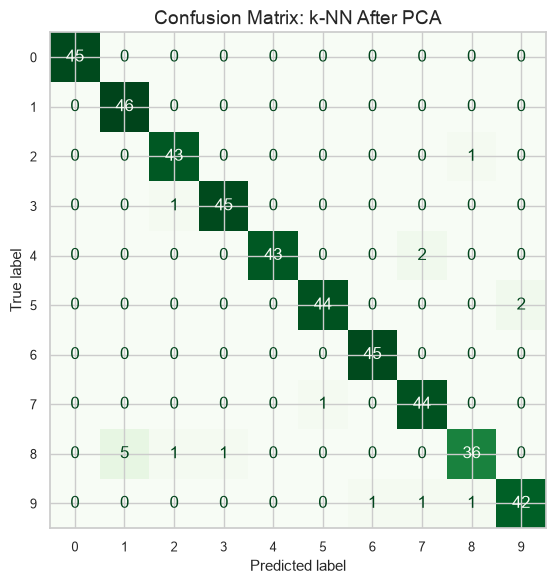

In [14]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test_digits,
    pca_predictions,
    cmap="Greens",
    values_format="d",
    ax=ax,
    colorbar=False,
)
ax.set_title("Confusion Matrix: k-NN After PCA")
plt.tight_layout()
plt.show()


In [15]:
classification_comparison = pd.DataFrame(
    [
        {
            "model": "k-NN without PCA",
            "dimensions": X_train_digits_scaled.shape[1],
            "accuracy": original_accuracy,
            "retained_variance": 1.0,
        },
        {
            "model": "k-NN with PCA",
            "dimensions": X_train_digits_pca.shape[1],
            "accuracy": pca_accuracy,
            "retained_variance": retained_variance,
        },
    ]
)
display(classification_comparison)


,model,dimensions,accuracy,retained_variance
0,k-NN without PCA,64,0.964444,1.00000
1,k-NN with PCA,31,0.962222,0.90255


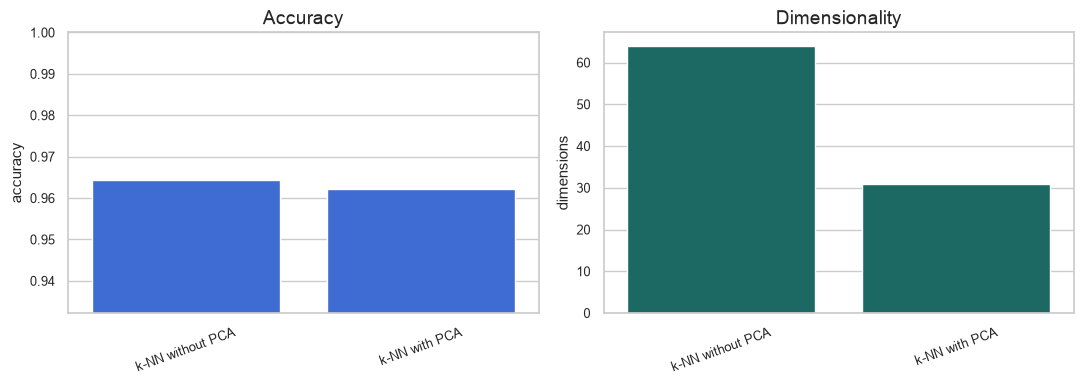

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.barplot(data=classification_comparison, x="model", y="accuracy", ax=axes[0], color="#2563EB")
axes[0].set_title("Accuracy")
axes[0].set_ylim(max(0, classification_comparison["accuracy"].min() - 0.03), 1.0)
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=classification_comparison, x="model", y="dimensions", ax=axes[1], color="#0F766E")
axes[1].set_title("Dimensionality")
axes[1].tick_params(axis="x", rotation=20)

for ax in axes:
    ax.set_xlabel("")

plt.tight_layout()
plt.show()


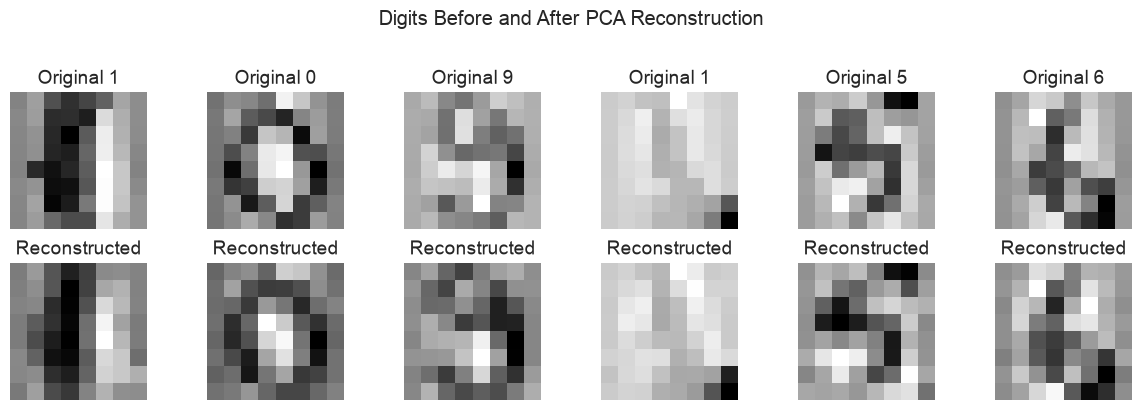

In [17]:
reconstruction_source = X_test_digits_scaled[:6]
reconstruction_scores = pca_digits_90.transform(reconstruction_source)
reconstruction_back = pca_digits_90.inverse_transform(reconstruction_scores)

fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for i in range(6):
    axes[0, i].imshow(reconstruction_source[i].reshape(8, 8), cmap="gray_r")
    axes[0, i].set_title(f"Original {y_test_digits[i]}")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstruction_back[i].reshape(8, 8), cmap="gray_r")
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.suptitle("Digits Before and After PCA Reconstruction", y=1.02)
plt.tight_layout()
plt.show()


**Classification interpretation.** PCA reduces the feature space while preserving most variance. Any small accuracy change should be interpreted jointly with the reduction in dimensionality and computational cost.


## 6. Two-dimensional visualization


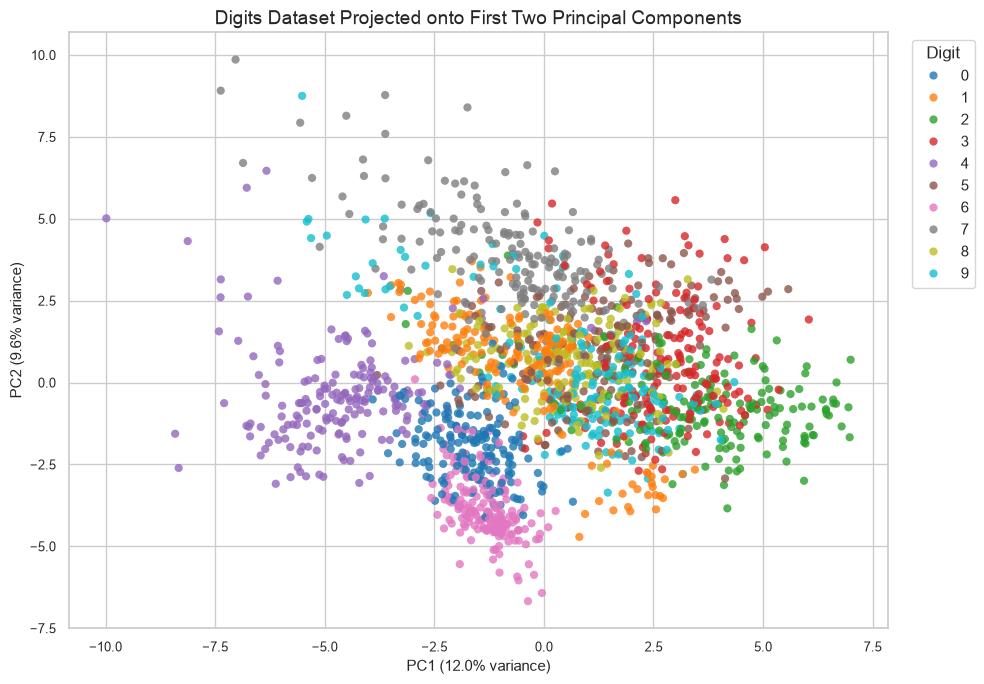

In [18]:
pca_digits_2d = PCA(n_components=2)
X_digits_2d = pca_digits_2d.fit_transform(StandardScaler().fit_transform(X_digits))

digits_projection = pd.DataFrame(
    {
        "PC1": X_digits_2d[:, 0],
        "PC2": X_digits_2d[:, 1],
        "digit": y_digits.astype(str),
    }
)

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=digits_projection,
    x="PC1",
    y="PC2",
    hue="digit",
    palette="tab10",
    s=35,
    alpha=0.8,
    linewidth=0,
    ax=ax,
)
ax.set_title("Digits Dataset Projected onto First Two Principal Components")
ax.set_xlabel(f"PC1 ({pca_digits_2d.explained_variance_ratio_[0] * 100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca_digits_2d.explained_variance_ratio_[1] * 100:.1f}% variance)")
ax.legend(title="Digit", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


**Projection interpretation.** The two-dimensional PCA map reveals partial class clustering but substantial overlap, confirming that two components are useful for visualization but insufficient as a complete discriminative representation.


## Conclusion

PCA compresses the digit representation while preserving at least 90% of the training-set variance. Compare the held-out test accuracy with the original-feature classifier to assess the trade-off. These results apply to this dataset and split only.
